# The Weight of Surveillance: statistics

How sure can we be about the headline results? This notebook adds tests and uncertainty to the medians in
[`docs/results_numbers.md`](../docs/results_numbers.md).

1. **Paired tests.** Every site was measured in all three consent states, so the states are compared site by
   site: no choice vs Accept, Reject vs Accept, no choice vs Reject (Wilcoxon signed-rank test, effect size,
   Holm correction).
2. **Bootstrap intervals** for the group medians.
3. **Lower bounds.** On sites where the browser ran out of memory after Accept, the count is a lower bound. The
   true median is bracketed by treating those sites once as measured and once as "infinitely large".
4. **Reject vs no choice: does tracking start at all?** A paired test on the share of sites with any tracking
   request.
5. **Sensitivity:** Germany only.

Data: the dbt marts in DuckDB (`data/warehouse/wos.duckdb`, main dataset `real`), sites with a consent banner, one
value per site and state (the median over that site's usable visits, as in `mart_site_consent_effect`). Run
`python scripts/dbt.py build` first. The notebook only reads the warehouse.

In [10]:
import os
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB = Path(os.environ.get("WOS_DB", ROOT / "data" / "warehouse" / "wos.duckdb"))
FIG_DIR = ROOT / "docs" / "figures"
DATASET = "real"
B = 10_000           # bootstrap resamples
SEED = 20261102      # fixed seed: the intervals are reproducible
ALPHA = 0.05

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
con = duckdb.connect(str(DB), read_only=True)
print(DB)

/Users/dinagudkova/Documents/Dev/Spiced/weight-of-surveillance-pilot/data/warehouse/wos.duckdb


## 1. Data

One row per site with a banner. Tracking requests per state come from `mart_site_consent_effect`; tracking
companies per state are computed the same way from `fct_visits` (median over the site's usable visits), because
the mart only stores companies after Accept.

In [11]:
sites = con.sql('''
    select site, site_domain, site_group_label as grp, site_group_order as grp_order, site_country,
           none_tracking_requests   as none_req,
           reject_tracking_requests as reject_req,
           accept_tracking_requests as accept_req,
           accept_is_lower_bound    as accept_lb
    from marts.mart_site_consent_effect
    where has_banner
''').df()

companies = con.sql(f'''
    select site,
           median(tracking_companies) filter (where mode = 'none')   as none_comp,
           median(tracking_companies) filter (where mode = 'reject') as reject_comp,
           median(tracking_companies) filter (where mode = 'accept') as accept_comp
    from marts.fct_visits
    where is_usable and dataset = '{DATASET}'
    group by site
''').df()

df = sites.merge(companies, on="site", how="left")
df["accept_lb"] = df["accept_lb"].fillna(False).astype(bool)
GROUPS = df.sort_values("grp_order")["grp"].unique().tolist()

overview = (df.groupby("grp", sort=False)
              .agg(sites=("site", "size"),
                   with_none=("none_req", "count"), with_reject=("reject_req", "count"),
                   with_accept=("accept_req", "count"), accept_lower_bound=("accept_lb", "sum"))
              .reindex(GROUPS))
overview.loc["All sites"] = overview.sum()
overview

,sites,with_none,with_reject,with_accept,accept_lower_bound
grp,,,,,
Media,165,164,81,143,60
Shopping,118,117,97,104,0
Services & entertainment,96,96,71,82,11
Finance & health,48,48,33,37,2
Public sector & education,10,10,8,8,0
Gambling,12,11,11,11,0
All sites,449,446,301,385,73


Check against the marts: 449 sites with a banner, 165 / 118 / 96 / 48 / 10 / 12 per group, and 60 / 0 / 11 / 2 /
0 / 0 Accept lower bounds.

## 2. Paired tests between the consent states

For each pair of states only sites measured in both enter the test. The **Wilcoxon signed-rank test** asks
whether the differences are symmetric around zero. Many sites have exactly the same value in both states (often 0
and 0); these ties are kept in the ranking (`zero_method="pratt"`), which is the more conservative choice when
zeros are this common.

Reported per test:

- `n`: sites with both values; `n_changed`: sites where the value differs;
- `share_higher`: share of sites where the second state is higher than the first;
- `median_diff`: median of the site-by-site differences (second minus first);
- `r_rb`: matched-pairs rank-biserial correlation, an effect size from −1 to 1 (1: the second state is higher
  on every site that changed);
- `p_holm`: p-value after Holm correction over all tests in the table.

After Accept the lower-bound sites enter with their observed (too low) counts. That can only shrink the
differences, so the tests against Accept are conservative.

In [12]:
PAIRS = [("none", "accept"), ("reject", "accept"), ("none", "reject")]
METRICS = {"req": "tracking requests", "comp": "tracking companies"}


def rank_biserial(diff):
    d = diff[diff != 0]
    if len(d) == 0:
        return 0.0
    ranks = stats.rankdata(np.abs(d))
    w_pos, w_neg = ranks[d > 0].sum(), ranks[d < 0].sum()
    return (w_pos - w_neg) / (w_pos + w_neg)


def paired_test(frame, a, b, metric):
    x = frame[[f"{a}_{metric}", f"{b}_{metric}"]].dropna()
    diff = (x.iloc[:, 1] - x.iloc[:, 0]).to_numpy()
    row = {"n": len(diff), "n_changed": int((diff != 0).sum()),
           "share_higher": (diff > 0).mean() if len(diff) else np.nan,
           "median_diff": np.median(diff) if len(diff) else np.nan,
           "r_rb": rank_biserial(diff), "p": np.nan}
    if row["n_changed"] >= 1 and len(diff) >= 6:
        row["p"] = stats.wilcoxon(diff, zero_method="pratt", alternative="two-sided").pvalue
    return row


def holm(p):
    p = np.asarray(p, dtype=float)
    out = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    order = np.argsort(p[ok])
    m = ok.sum()
    adj = np.maximum.accumulate((m - np.arange(m)) * p[ok][order])
    res = np.empty(m)
    res[order] = np.minimum(adj, 1)
    out[ok] = res
    return out


rows = []
for grp in GROUPS + ["All sites"]:
    frame = df if grp == "All sites" else df[df["grp"] == grp]
    for metric, label in METRICS.items():
        for a, b in PAIRS:
            rows.append({"group": grp, "metric": label, "comparison": f"{a} → {b}",
                         **paired_test(frame, a, b, metric)})

tests = pd.DataFrame(rows)
tests["p_holm"] = holm(tests["p"])
tests["significant"] = tests["p_holm"] < ALPHA
tests.round({"share_higher": 2, "median_diff": 1, "r_rb": 2}).style.format(
    {"p": "{:.1e}", "p_holm": "{:.1e}"}, na_rep="–")

,group,metric,comparison,n,n_changed,share_higher,median_diff,r_rb,p,p_holm,significant
0,Media,tracking requests,none → accept,142,142,1.000000,1067.000000,1.000000,4.7e-25,1.7e-23,True
1,Media,tracking requests,reject → accept,80,80,0.990000,859.000000,1.000000,8.3e-15,2.3e-13,True
2,Media,tracking requests,none → reject,81,52,0.620000,2.000000,0.960000,5.4e-11,1.3e-09,True
3,Media,tracking companies,none → accept,142,140,0.990000,97.500000,1.000000,4.9e-25,1.7e-23,True
4,Media,tracking companies,reject → accept,80,79,0.990000,84.500000,1.000000,8.0e-15,2.3e-13,True
5,Media,tracking companies,none → reject,81,45,0.540000,1.000000,0.970000,3.2e-10,7.3e-09,True
6,Shopping,tracking requests,none → accept,103,98,0.930000,74.000000,1.000000,2.4e-18,8.2e-17,True
7,Shopping,tracking requests,reject → accept,93,87,0.880000,72.000000,0.990000,4.6e-16,1.5e-14,True
8,Shopping,tracking requests,none → reject,96,58,0.530000,1.000000,0.830000,5.1e-09,1.1e-07,True
9,Shopping,tracking companies,none → accept,103,93,0.880000,10.000000,1.000000,5.4e-18,1.8e-16,True


Groups with very few sites (public sector with a banner: 10, gambling: 12) can reach significance only for very
large and consistent effects; "not significant" there means "too few sites to tell", not "no effect". Tests with
fewer than 6 pairs are not run.

## 3. Bootstrap intervals for the group medians

Percentile bootstrap: the sites of a group are resampled with replacement 10,000 times and the median is taken each
time; the 2.5% and 97.5% quantiles form the 95% interval. With many identical values (zeros) the median can only
take a few values, so an interval like [0, 0] is possible and means the median is 0 in practically every
resample.

In [13]:
rng = np.random.default_rng(SEED)


def boot_median(values, b=B):
    x = np.asarray(values, dtype=float)
    x = x[~np.isnan(x)]
    if len(x) == 0:
        return np.nan, np.nan, np.nan, 0
    idx = rng.integers(0, len(x), size=(b, len(x)))
    meds = np.median(x[idx], axis=1)
    # With +inf values (lower-bound sites in section 4) interpolation would give inf - inf = NaN,
    # so the quantiles are then taken without interpolation.
    method = "inverted_cdf" if np.isinf(meds).any() else "linear"
    lo, hi = np.quantile(meds, [ALPHA / 2, 1 - ALPHA / 2], method=method)
    return np.median(x), lo, hi, len(x)


boot_rows = []
for grp in GROUPS + ["All sites"]:
    frame = df if grp == "All sites" else df[df["grp"] == grp]
    for col, label in [("none_req", "requests, no choice"), ("reject_req", "requests, Reject"),
                       ("accept_req", "requests, Accept"), ("reject_comp", "companies, Reject"),
                       ("accept_comp", "companies, Accept")]:
        med, lo, hi, n = boot_median(frame[col])
        boot_rows.append({"group": grp, "metric": label, "n": n, "median": med, "ci_low": lo, "ci_high": hi})

boot = pd.DataFrame(boot_rows)
boot_wide = boot.pivot_table(index="group", columns="metric", values=["median", "ci_low", "ci_high"],
                             sort=False).reindex(GROUPS + ["All sites"])


def fmt(m, lo, hi):
    return "–" if np.isnan(m) else f"{m:g} [{lo:g}–{hi:g}]"


ci_table = pd.DataFrame({
    metric: [fmt(*boot.loc[(boot.group == g) & (boot.metric == metric), ["median", "ci_low", "ci_high"]]
                 .iloc[0]) for g in GROUPS + ["All sites"]]
    for metric in boot["metric"].unique()}, index=GROUPS + ["All sites"])
ci_table

,"requests, no choice","requests, Reject","requests, Accept","companies, Reject","companies, Accept"
Media,0 [0–0],4 [1–15],1069 [995–1139],1 [1–2],100 [94–103]
Shopping,0 [0–1],3 [1–4],81 [61–95],1 [0–1],11.5 [8.5–21.5]
Services & entertainment,0 [0–0],2 [0–4],91 [53–192.5],1 [0–1],9 [4.5–33.5]
Finance & health,0 [0–0],0 [0–0],28 [9–54],0 [0–0],4 [2–8]
Public sector & education,0 [0–0],0 [0–0],0.5 [0–6],0 [0–0],0 [0–2]
Gambling,0 [0–7],2 [0–8],37 [9–47],1 [0–2],5 [3–9]
All sites,0 [0–0],2 [1–3],138 [111–211],1 [0–1],29 [23–37]


## 4. Lower bounds after Accept: bracketing the true median

On a lower-bound site the true count after Accept is *at least* the observed one. So:

- the median of the observed values is a **lower bound** for the true median;
- the median with every lower-bound site set to +∞ is an **upper bound** (no true value can be larger).

If the two coincide, the lower bounds do not affect the median at all. The bootstrap interval for the bracket uses
the lower end of the first and the upper end of the second.

In [14]:
bracket_rows = []
for grp in GROUPS + ["All sites"]:
    frame = df if grp == "All sites" else df[df["grp"] == grp]
    for col, label in [("accept_req", "requests"), ("accept_comp", "companies")]:
        x = frame[[col, "accept_lb"]].dropna(subset=[col])
        if x.empty:
            continue
        observed = x[col].to_numpy(dtype=float)
        censored = np.where(x["accept_lb"], np.inf, observed)
        low, low_ci, _, n = boot_median(observed)
        high, _, high_ci, _ = boot_median(censored)
        bracket_rows.append({"group": grp, "metric": f"Accept, {label}", "n": n,
                             "lower_bound_sites": int(x["accept_lb"].sum()),
                             "median_at_least": low, "median_at_most": high,
                             "ci_low": low_ci, "ci_high": high_ci})

bracket = pd.DataFrame(bracket_rows)
bracket.replace(np.inf, "unbounded")

,group,metric,n,lower_bound_sites,median_at_least,median_at_most,ci_low,ci_high
0,Media,"Accept, requests",143,60,1069.0,1347.0,1006.0,1917.0
1,Media,"Accept, companies",143,60,100.0,114.0,94.0,unbounded
2,Shopping,"Accept, requests",104,0,81.0,81.0,62.0,94.5
3,Shopping,"Accept, companies",104,0,11.5,11.5,8.5,21.5
4,Services & entertainment,"Accept, requests",82,11,91.0,91.0,53.0,192.5
5,Services & entertainment,"Accept, companies",82,11,9.0,9.0,4.5,33.5
6,Finance & health,"Accept, requests",37,2,28.0,28.0,9.0,54.0
7,Finance & health,"Accept, companies",37,2,4.0,4.0,2.0,8.0
8,Public sector & education,"Accept, requests",8,0,0.5,0.5,0.0,6.0
9,Public sector & education,"Accept, companies",8,0,0.0,0.0,0.0,2.0


## 5. Reject vs no choice: does tracking start at all?

The medians after Reject and without a choice are both close to 0, so the question is better asked as a yes/no per
site: is there *any* tracking request in the 30-second window? The paired test for a yes/no outcome is
**McNemar's test** (exact version: a binomial test on the sites that changed).

In [15]:
mc_rows = []
for grp in GROUPS + ["All sites"]:
    frame = df if grp == "All sites" else df[df["grp"] == grp]
    x = frame[["none_req", "reject_req"]].dropna()
    none_any, reject_any = x["none_req"] > 0, x["reject_req"] > 0
    only_reject = int((~none_any & reject_any).sum())
    only_none = int((none_any & ~reject_any).sum())
    p = (stats.binomtest(only_reject, only_reject + only_none, 0.5).pvalue
         if only_reject + only_none > 0 else np.nan)
    mc_rows.append({"group": grp, "n": len(x),
                    "share_any_no_choice": none_any.mean(), "share_any_reject": reject_any.mean(),
                    "only_after_reject": only_reject, "only_without_choice": only_none, "p": p})

mcnemar = pd.DataFrame(mc_rows)
mcnemar["p_holm"] = holm(mcnemar["p"])
mcnemar.round({"share_any_no_choice": 2, "share_any_reject": 2}).style.format(
    {"p": "{:.1e}", "p_holm": "{:.1e}"}, na_rep="–")

,group,n,share_any_no_choice,share_any_reject,only_after_reject,only_without_choice,p,p_holm
0,Media,81,0.320000,0.680000,30,1,3.0e-08,1.8e-07
1,Shopping,96,0.500000,0.620000,15,3,7.5e-03,3.0e-02
2,Services & entertainment,71,0.210000,0.560000,25,0,6.0e-08,3.0e-07
3,Finance & health,33,0.120000,0.300000,6,0,3.1e-02,9.4e-02
4,Public sector & education,8,0.000000,0.120000,1,0,1.0e+00,1.0e+00
5,Gambling,10,0.300000,0.500000,2,0,5.0e-01,1.0e+00
6,All sites,299,0.320000,0.570000,79,4,4.0e-19,2.8e-18


Note: the window in "no choice" starts after the page has loaded (about 4 s); after Reject it starts at the
click. Tracking that a site sends during page load is therefore in neither window (see "Before any choice" in the
results document).

## 6. Sensitivity: Germany only

The sample contains four Swiss and two Austrian sites (`site_country`). Leaving them out:

In [16]:
sens_rows = []
for grp in GROUPS + ["All sites"]:
    frame = df if grp == "All sites" else df[df["grp"] == grp]
    de = frame[frame["site_country"] == "DE"]
    sens_rows.append({"group": grp, "sites": len(frame), "sites_de": len(de),
                      "accept_req_all": frame["accept_req"].median(), "accept_req_de": de["accept_req"].median(),
                      "accept_comp_all": frame["accept_comp"].median(), "accept_comp_de": de["accept_comp"].median()})
pd.DataFrame(sens_rows).set_index("group")

,sites,sites_de,accept_req_all,accept_req_de,accept_comp_all,accept_comp_de
group,,,,,,
Media,165,160,1069.0,1075.0,100.0,99.5
Shopping,118,117,81.0,81.0,11.5,12.0
Services & entertainment,96,96,91.0,91.0,9.0,9.0
Finance & health,48,48,28.0,28.0,4.0,4.0
Public sector & education,10,10,0.5,0.5,0.0,0.0
Gambling,12,12,37.0,37.0,5.0,5.0
All sites,449,443,138.0,138.0,29.0,29.0


## 7. Figure: group medians with 95% intervals

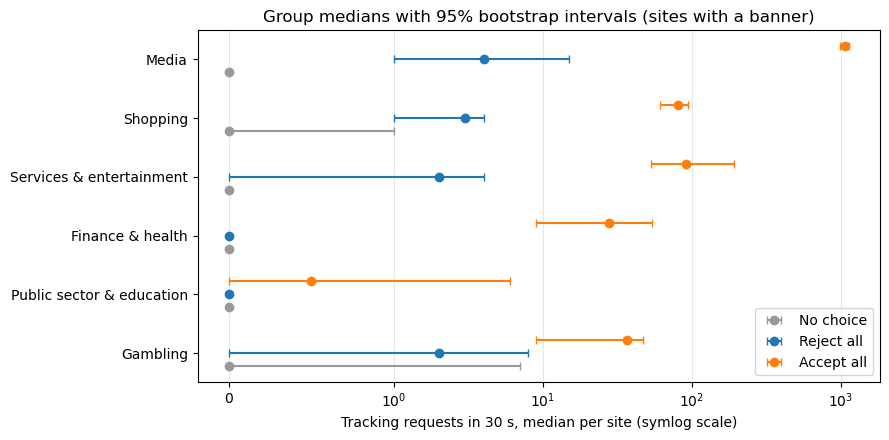

In [17]:
FIG_DIR.mkdir(parents=True, exist_ok=True)
states = [("requests, no choice", "No choice", "0.6"), ("requests, Reject", "Reject all", "tab:blue"),
          ("requests, Accept", "Accept all", "tab:orange")]
fig, ax = plt.subplots(figsize=(9, 4.5))
ypos = np.arange(len(GROUPS))[::-1]
for i, (metric, label, color) in enumerate(states):
    sub = boot[boot["metric"] == metric].set_index("group").reindex(GROUPS)
    y = ypos + (i - 1) * 0.22
    ax.errorbar(sub["median"], y,
                xerr=[sub["median"] - sub["ci_low"], sub["ci_high"] - sub["median"]],
                fmt="o", color=color, label=label, capsize=3)
ax.set_xscale("symlog", linthresh=1)
ax.set_yticks(ypos, GROUPS)
ax.set_xlabel("Tracking requests in 30 s, median per site (symlog scale)")
ax.set_title("Group medians with 95% bootstrap intervals (sites with a banner)")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "medians_bootstrap_ci.png", dpi=150)
plt.show()

## 8. Summary in numbers

Generated from the tables above, for `docs/results_numbers.md` and the presentation.

In [18]:
def p_text(p):
    return "–" if np.isnan(p) else ("p < 0.001" if p < 0.001 else f"p = {p:.3f}")


lines = []
for comparison in ["none → accept", "reject → accept", "none → reject"]:
    t = tests[(tests.group == "All sites") & (tests.metric == "tracking requests") & (tests.comparison == comparison)].iloc[0]
    lines.append(f"All sites, tracking requests, {comparison}: higher on {t.share_higher:.0%} of {t.n} sites, "
                 f"median difference {t.median_diff:g}, r = {t.r_rb:.2f}, {p_text(t.p_holm)} (Holm)")
for _, b in bracket[bracket.metric == "Accept, requests"].iterrows():
    hi = "unbounded" if np.isinf(b.median_at_most) else f"{b.median_at_most:g}"
    lines.append(f"{b.group}, median requests after Accept: between {b.median_at_least:g} and {hi} "
                 f"(95% interval {b.ci_low:g}–{f'{b.ci_high:g}' if np.isfinite(b.ci_high) else 'unbounded'}; "
                 f"{b.lower_bound_sites} lower-bound sites)")
m = mcnemar[mcnemar.group == "All sites"].iloc[0]
lines.append(f"Any tracking in the window: {m.share_any_no_choice:.0%} of sites without a choice vs "
             f"{m.share_any_reject:.0%} after Reject ({m.only_after_reject} sites only after Reject, "
             f"{m.only_without_choice} only without a choice; {p_text(m.p_holm)})")
n_sig = int(tests.significant.sum())
lines.append(f"{n_sig} of {tests.p.notna().sum()} paired tests significant after Holm correction (α = {ALPHA})")
print("\n".join(lines))

All sites, tracking requests, none → accept: higher on 95% of 382 sites, median difference 135.5, r = 1.00, p < 0.001 (Holm)
All sites, tracking requests, reject → accept: higher on 90% of 292 sites, median difference 83.5, r = 0.99, p < 0.001 (Holm)
All sites, tracking requests, none → reject: higher on 51% of 299 sites, median difference 1, r = 0.92, p < 0.001 (Holm)
Media, median requests after Accept: between 1069 and 1347 (95% interval 1006–1917; 60 lower-bound sites)
Shopping, median requests after Accept: between 81 and 81 (95% interval 62–94.5; 0 lower-bound sites)
Services & entertainment, median requests after Accept: between 91 and 91 (95% interval 53–192.5; 11 lower-bound sites)
Finance & health, median requests after Accept: between 28 and 28 (95% interval 9–54; 2 lower-bound sites)
Public sector & education, median requests after Accept: between 0.5 and 0.5 (95% interval 0–6; 0 lower-bound sites)
Gambling, median requests after Accept: between 37 and 37 (95% interval 9–47